In [2]:
%pip install matplotlib numpy tensorflow


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
import warnings
from tensorflow import keras
from tensorflow.keras import layers

I0000 00:00:1794729405.172352   33526 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794729406.206838   33526 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794729408.845681   33526 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
data = np.load('cifar-10-python.npz')
x_train, y_train = data['x_train'], data['y_train'].flatten()
x_test, y_test = data['x_test'], data['y_test'].flatten()

print(x_train.shape)

(50000, 32, 32, 3)


In [6]:
m,n=np.max(x_train),np.min(x_train)
nor=m-n
print(f"Max pixel value {m}")
print(f"Min pixel value {n}")
x_train,x_test=x_train/nor,x_test/nor

Max pixel value 1.0
Min pixel value 0.0


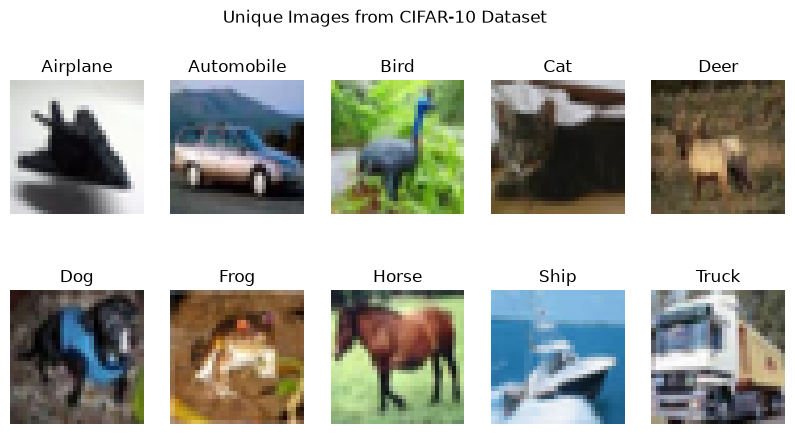

In [7]:
class_names = ["Airplane", "Automobile", "Bird", "Cat", "Deer",
               "Dog", "Frog", "Horse", "Ship", "Truck"]

unique_labels, idx = np.unique(y_train, return_index=True)
fig, ax = plt.subplots(2, 5, figsize=(10, 5))
for i, label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]])
    ax.flat[i].set_title(class_names[label])
    ax.flat[i].axis('off')
plt.suptitle("Unique Images from CIFAR-10 Dataset")
plt.show()

In [8]:
model1 = keras.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model1.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history1 = model1.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss1, acc1 = model1.evaluate(x_test, y_test, verbose=2)
print(f"Model 1 Test Accuracy: {acc1 * 100:.2f}%")

/home/don/.venv/lib64/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1794729522.582795   33526 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

W0000 00:00:1794729527.376789   33526 cpu_allocator_impl.cc:174] Allocation of 491520000 exceeds 10% of free system memory.


Epoch 1/10


W0000 00:00:1794729537.166388   33526 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


1250/1250 - 9s - 8ms/step - accuracy: 0.1668 - loss: 2.2458 - val_accuracy: 0.2448 - val_loss: 2.1378
Epoch 2/10
1250/1250 - 7s - 6ms/step - accuracy: 0.2345 - loss: 2.1096 - val_accuracy: 0.2883 - val_loss: 2.0109
Epoch 3/10
1250/1250 - 6s - 5ms/step - accuracy: 0.2691 - loss: 2.0194 - val_accuracy: 0.3079 - val_loss: 1.9430
Epoch 4/10
1250/1250 - 6s - 5ms/step - accuracy: 0.2906 - loss: 1.9620 - val_accuracy: 0.3281 - val_loss: 1.8958
Epoch 5/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3086 - loss: 1.9179 - val_accuracy: 0.3366 - val_loss: 1.8639
Epoch 6/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3210 - loss: 1.8907 - val_accuracy: 0.3460 - val_loss: 1.8394
Epoch 7/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3296 - loss: 1.8663 - val_accuracy: 0.3535 - val_loss: 1.8179
Epoch 8/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3390 - loss: 1.8438 - val_accuracy: 0.3594 - val_loss: 1.7985
Epoch 9/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3466 - loss: 1.8230 - val_accuracy: 0.3695 - val_loss: 1

W0000 00:00:1794729596.934454   33526 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


313/313 - 1s - 2ms/step - accuracy: 0.3845 - loss: 1.7416
Model 1 Test Accuracy: 38.45%


In [9]:
model2 = keras.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history2 = model1.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss2, acc2 = model2.evaluate(x_test, y_test, verbose=2)
print(f"Model 1 Test Accuracy: {acc2 * 100:.2f}%")

W0000 00:00:1794729646.924902   33526 cpu_allocator_impl.cc:174] Allocation of 491520000 exceeds 10% of free system memory.


Epoch 1/10


W0000 00:00:1794729656.220611   33526 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


1250/1250 - 8s - 6ms/step - accuracy: 0.3609 - loss: 1.7891 - val_accuracy: 0.3777 - val_loss: 1.7509
Epoch 2/10
1250/1250 - 7s - 5ms/step - accuracy: 0.3664 - loss: 1.7726 - val_accuracy: 0.3840 - val_loss: 1.7369
Epoch 3/10
1250/1250 - 6s - 5ms/step - accuracy: 0.3663 - loss: 1.7646 - val_accuracy: 0.3919 - val_loss: 1.7221
Epoch 4/10
1250/1250 - 7s - 5ms/step - accuracy: 0.3765 - loss: 1.7471 - val_accuracy: 0.3937 - val_loss: 1.7087
Epoch 5/10
1250/1250 - 7s - 6ms/step - accuracy: 0.3799 - loss: 1.7361 - val_accuracy: 0.3983 - val_loss: 1.6985
Epoch 6/10
1250/1250 - 7s - 6ms/step - accuracy: 0.3846 - loss: 1.7265 - val_accuracy: 0.4034 - val_loss: 1.6860
Epoch 7/10
1250/1250 - 8s - 6ms/step - accuracy: 0.3907 - loss: 1.7096 - val_accuracy: 0.4067 - val_loss: 1.6780
Epoch 8/10
1250/1250 - 8s - 6ms/step - accuracy: 0.3927 - loss: 1.7005 - val_accuracy: 0.4122 - val_loss: 1.6674
Epoch 9/10
1250/1250 - 9s - 7ms/step - accuracy: 0.3940 - loss: 1.6922 - val_accuracy: 0.4145 - val_loss: 1

In [10]:
model3 = keras.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model3.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history3 = model1.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss3, acc3 = model3.evaluate(x_test, y_test, verbose=2)
print(f"Model 1 Test Accuracy: {acc3 * 100:.2f}%")

Epoch 1/10
1250/1250 - 8s - 6ms/step - accuracy: 0.4016 - loss: 1.6747 - val_accuracy: 0.4208 - val_loss: 1.6406
Epoch 2/10
1250/1250 - 8s - 6ms/step - accuracy: 0.4086 - loss: 1.6656 - val_accuracy: 0.4238 - val_loss: 1.6324
Epoch 3/10
1250/1250 - 6s - 5ms/step - accuracy: 0.4084 - loss: 1.6562 - val_accuracy: 0.4251 - val_loss: 1.6268
Epoch 4/10
1250/1250 - 7s - 5ms/step - accuracy: 0.4119 - loss: 1.6501 - val_accuracy: 0.4302 - val_loss: 1.6179
Epoch 5/10
1250/1250 - 6s - 5ms/step - accuracy: 0.4137 - loss: 1.6425 - val_accuracy: 0.4338 - val_loss: 1.6141
Epoch 6/10
1250/1250 - 7s - 5ms/step - accuracy: 0.4156 - loss: 1.6334 - val_accuracy: 0.4387 - val_loss: 1.6033
Epoch 7/10
1250/1250 - 6s - 5ms/step - accuracy: 0.4204 - loss: 1.6225 - val_accuracy: 0.4363 - val_loss: 1.5969
Epoch 8/10
1250/1250 - 6s - 5ms/step - accuracy: 0.4252 - loss: 1.6166 - val_accuracy: 0.4426 - val_loss: 1.5915
Epoch 9/10
1250/1250 - 6s - 5ms/step - accuracy: 0.4275 - loss: 1.6118 - val_accuracy: 0.4452 - 

In [ ]:
image_index = int(input("Enter image index (0-9999): "))

plt.imshow(x_test[image_index])
plt.show()

prediction = model3.predict(x_test[image_index].reshape(1, 32, 32, 3), verbose=0)

print("Predicted Class:", class_names[np.argmax(prediction)])
print("Actual Class:", class_names[y_test[image_index]])

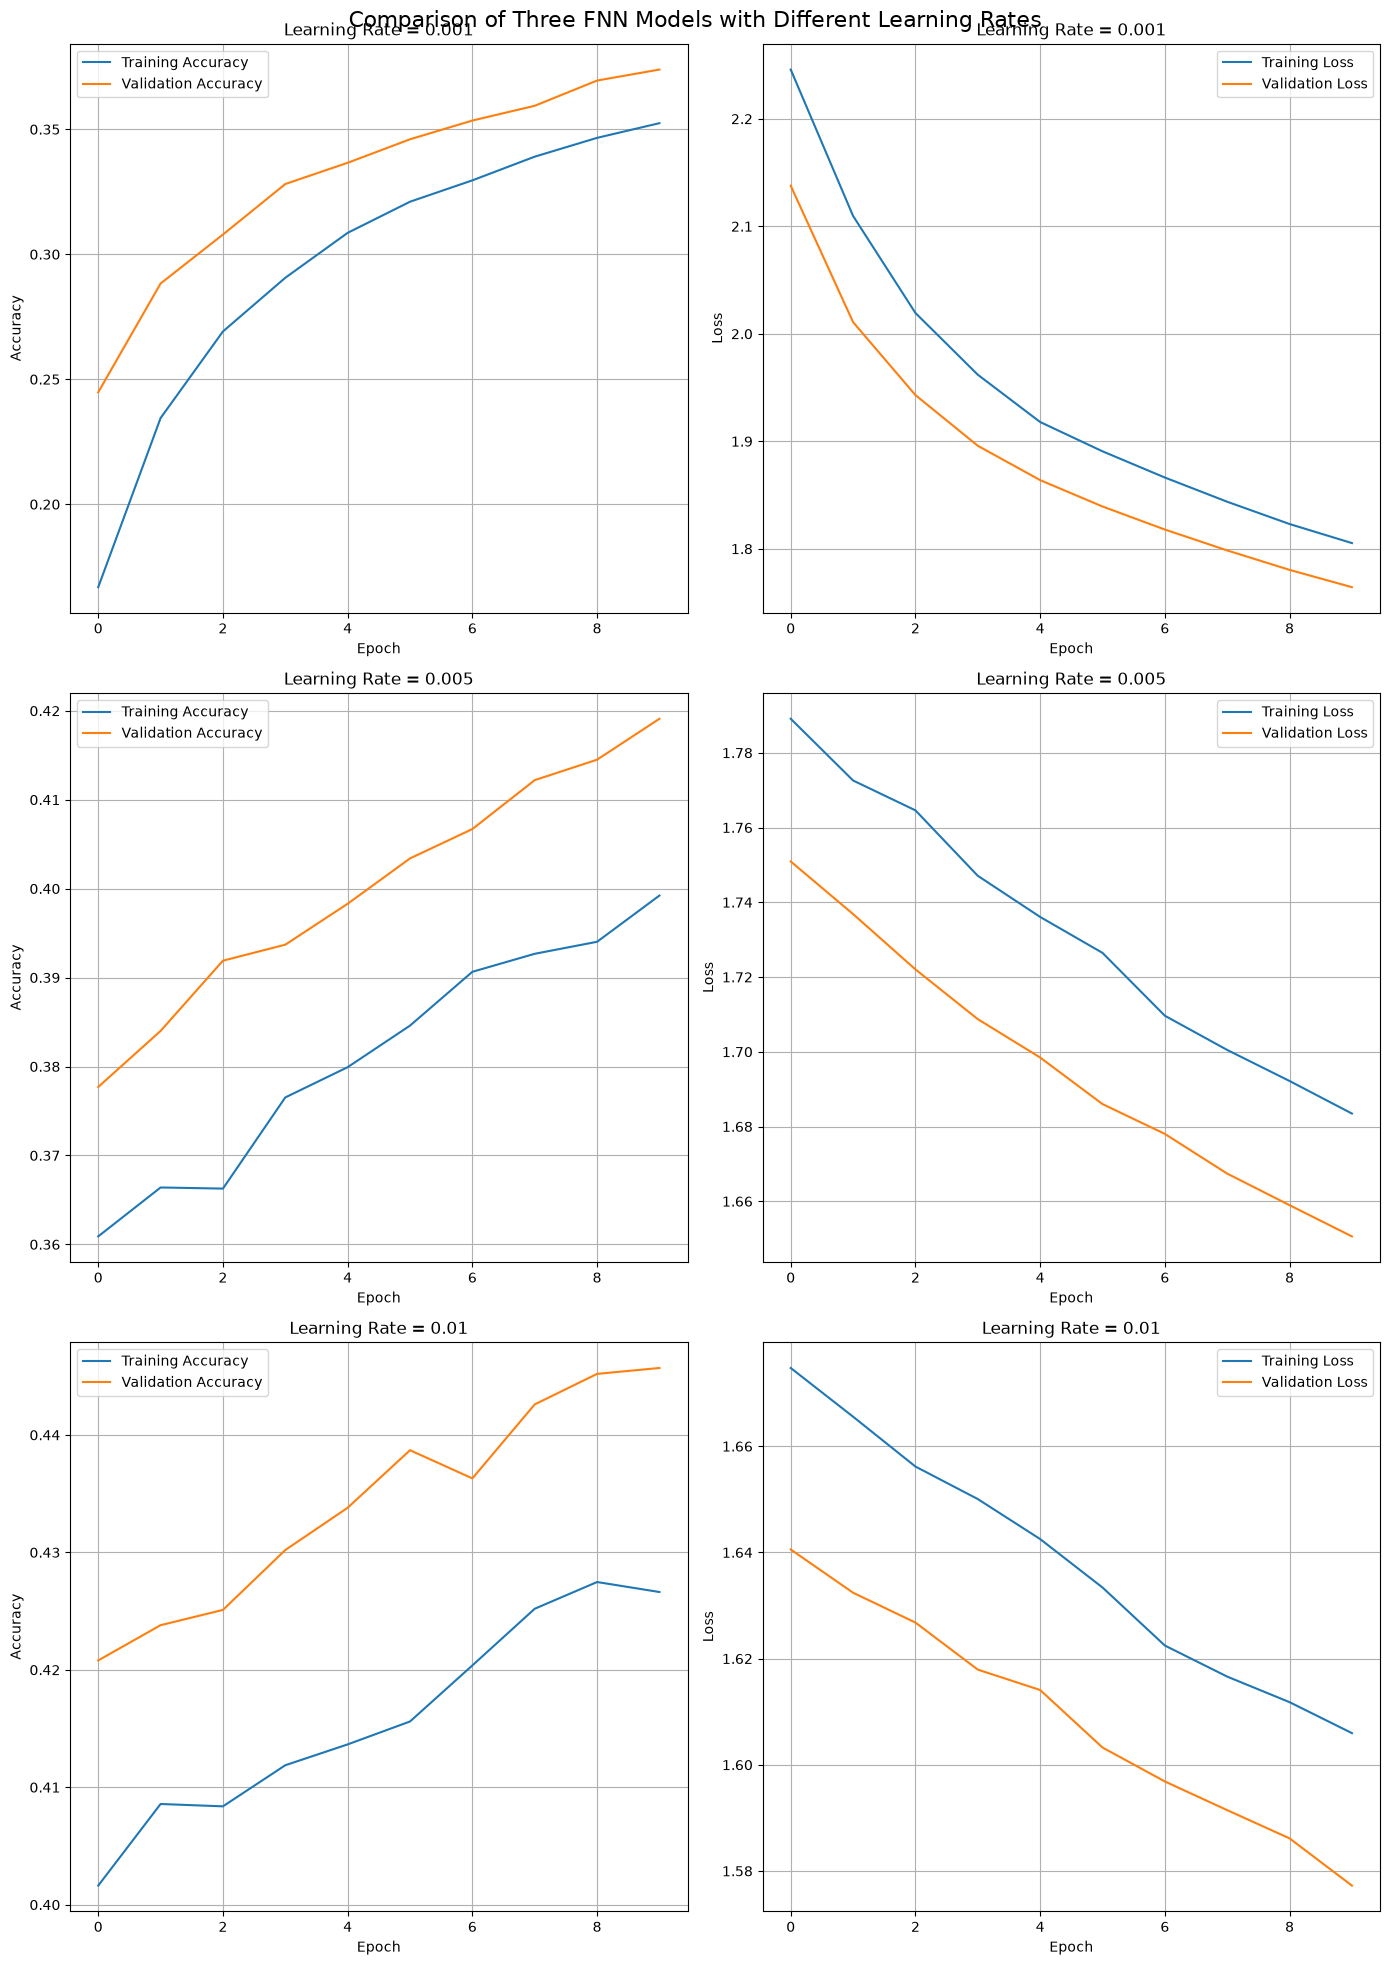

In [12]:
histories = [history1, history2, history3]
learning_rates = [0.001, 0.005, 0.01]

fig, axes = plt.subplots(3, 2, figsize=(14, 20))

for i, history in enumerate(histories):
    axes[i, 0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[i, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[i, 0].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Accuracy')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    axes[i, 1].plot(history.history['loss'], label='Training Loss')
    axes[i, 1].plot(history.history['val_loss'], label='Validation Loss')
    axes[i, 1].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Loss')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.suptitle('Comparison of Three FNN Models with Different Learning Rates', fontsize=16)
plt.tight_layout()
plt.show()

In [49]:
for h in histories:
    print({k: v for k, v in h.history.items()})

{'accuracy': [0.875124990940094], 'loss': [0.42035582661628723], 'val_accuracy': [0.9144999980926514], 'val_loss': [0.2971084415912628]}
{'accuracy': [0.6121249794960022], 'loss': [1.2611839771270752], 'val_accuracy': [0.8760833144187927], 'val_loss': [0.4714221954345703]}
{'accuracy': [0.612666666507721], 'loss': [1.2329061031341553], 'val_accuracy': [0.8777499794960022], 'val_loss': [0.46643421053886414]}
